### Aim 1 - figure 2: (was originally in aim2.)
#### 1. figures - Comparison of full trial (1000ms) to lexical selection window (350ms)

In [1]:
%logstart -r aim2_fig1.py 

Activating auto-logging. Current session state plus future input saved.
Filename       : aim2_fig1.py
Mode           : backup
Output logging : False
Raw input log  : True
Timestamping   : False
State          : active


Set working directory:

In [2]:
project_path = '/project_data/volume0/tpirnia/data/EEGWS'
results_path = '/data/across_subjects/results/clean/aim-2/'

Data locations:

In [3]:
full_dfname = 'results_c_avg_w1000_block5-5_ridge-CLEAN.csv'
lexs_dfname = 'results_c_avg_w350_block5-5_ridge-CLEAN.csv'


In [4]:
datafiles = [full_dfname, lexs_dfname,]

In [5]:
exclude_subjects = ['EP24']

In [6]:
figure_name = 'Figure2-Comparison_of_epoch_length.png'

In [7]:
ttest_fname = project_path + '/data/across_subjects/results/clean/ttest.csv'

Initialize:

In [7]:

import os, sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits import axes_grid1
from matplotlib import colors
import matplotlib as mpl
import seaborn as sns

from scipy.stats import ttest_rel

In [9]:
sys.path.append(project_path + '/maybe_repo')
from utils.utils import save_output

In [8]:

plt.rcParams.update(plt.rcParamsDefault)
%matplotlib inline
plt.style.use('seaborn-darkgrid')
plt.style.use('seaborn-poster')

In [9]:
main_df = []
for _fname in datafiles:
    # load file
    _df = pd.read_csv((project_path
                          + results_path
                          + _fname),
                     )
    # add to list
    main_df.append(_df)
    

##### 1. Prep Data Frame

    - Concatenate data sets

In [10]:
# concatenate
main_df = pd.concat(main_df,
                    ignore_index=True)
main_df.reset_index(inplace=True, 
                    drop=True)


    - Update columns:

In [11]:
col_renames={'subject': 'Subject',
             'classifier':'Classifier', 
             'window': 'Trial Length',
             'train_accuracy':'Train Accuracy', 
             't_500': 'Test Accuracy',
            }
main_df.rename(columns=col_renames,
               inplace=True)

    - Remove Subject EP24

In [12]:
main_df = main_df[~main_df['Subject'].isin(exclude_subjects)]
main_df.reset_index(inplace=True,
                    drop=True)


    - Categorize subjects

In [13]:
# change subjects to ordered type
subjects = main_df['Subject'].unique()
_cattype = pd.api.types.CategoricalDtype(categories=subjects, 
                                         ordered=True)
main_df['Subject']=main_df['Subject'].astype(_cattype)


    - Rename Classifiers

In [14]:
clfs = {'ridge':'Ridge Classifer',}
for _c in clfs:
    _inds = (main_df['Classifier'] == _c)
    main_df.loc[_inds,'Classifier'] = clfs[_c]

_cattype = pd.api.types.CategoricalDtype(categories=list(clfs.values()),
                                         ordered=True)
main_df['Classifier'] = main_df['Classifier'].astype(_cattype)


    - Preview DataFrame

In [15]:
# main_df.head(5)

,Subject,Classifier,Trial Length,step,w_train,Train Accuracy,Test Accuracy
0,EP03,Ridge Classifer,1000,0,0,0.665000,0.666667
1,EP05,Ridge Classifer,1000,0,0,0.578333,0.650000
2,EP06,Ridge Classifer,1000,0,0,0.721667,0.716667
3,EP07,Ridge Classifer,1000,0,0,0.933333,0.916667
4,EP09,Ridge Classifer,1000,0,0,0.583333,0.616667


In [15]:
# Dataframe for train/test classification 
_df = main_df.melt(id_vars=['Subject',
                            'Classifier',
                            'Trial Length',
                            'step',
                            'w_train'],
                   var_name='Performance',
                   value_name='Accuracy')

_inds_tr, _inds_te = (_df['Performance'] == 'Train Accuracy'),(_df['Performance'] == 'Test Accuracy')
_df.loc[_inds_tr,'Performance'] = 'Train'
_df.loc[_inds_te,'Performance'] = 'Test'


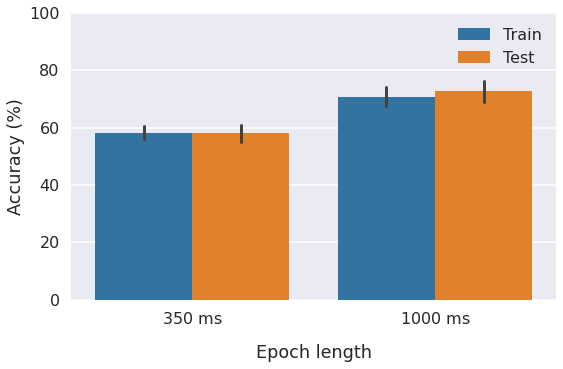

In [16]:
# Train and test Accuracy per classifier for full trial length (cue to 1000ms)
_figdims = (8.7, 5.27)
_fig, _ax = plt.subplots(figsize=_figdims)
_g = sns.barplot(y='Accuracy',
                 x='Trial Length',
                 hue='Performance',
                 data=_df,
                 ax=_ax, 
                 errwidth=3,
                 ci=95)

locs, _ = plt.yticks()
_ax.xaxis.labelpad = 17
xticks = ['$350$ ms','$1000$ ms']
_ax.set(ylabel='Accuracy (%)', 
        ylim=[0,1],
        yticks=locs, 
        yticklabels=list(map(int,locs*100)),
        xticklabels=xticks,
        xlabel='Epoch length')
plt.gca().legend().set_title('')
plt.savefig((project_path 
             + results_path 
             + figure_name[:-4]
             + '_traintest.png'),
            dpi=450, 
            bbox_inches = "tight")
plt.show()


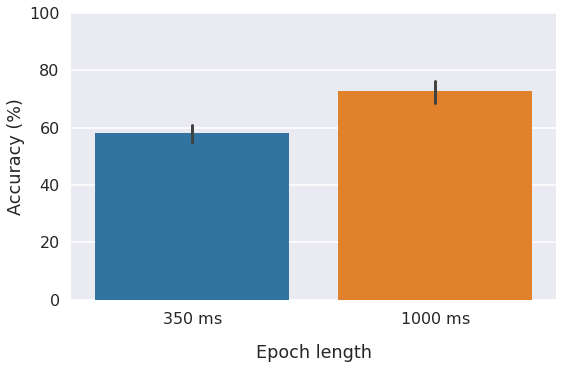

In [26]:
# Test Accuracy per classifier for full trial length (cue to 1000ms)
_figdims = (8.7, 5.27)
_fig, _ax = plt.subplots(figsize=_figdims)
_g = sns.barplot(y='Test Accuracy',
                 x='Trial Length',
                 data=main_df,
                 ax=_ax, 
                 errwidth=3,
                 ci=95)

locs, _ = plt.yticks()
_ax.xaxis.labelpad = 17
xticks = ['$350$ ms','$1000$ ms']
_ax.set(ylabel='Accuracy (%)', 
        ylim=[0,1],
        yticks=locs, 
        yticklabels=list(map(int,locs*100)),
        xticklabels=xticks,
        xlabel='Epoch length')
plt.savefig((project_path 
             + results_path 
             + figure_name),
            dpi=450, 
            bbox_inches = "tight")
plt.show()


In [17]:
# make df of descriptive statistics
stat_df = main_df.drop(columns=['step',
                                'w_train',
                                'Classifier'],
                      ).groupby(by=('Trial Length'),
                               ).agg(['min', 'max','mean','std','sem','var']) * 100
stat_df


Train Accuracy                                            \
                        min        max       mean       std       sem   
Trial Length                                                            
350               47.833333  71.333333  58.178571  6.268992  1.184728   
1000              55.500000  93.333333  70.845238  9.755122  1.843545   

                       Test Accuracy                                   \
                   var           min        max       mean        std   
Trial Length                                                            
350           0.393003     43.333333  76.666667  58.095238   8.072642   
1000          0.951624     56.666667  91.666667  72.678571  10.396851   

                                  
                   sem       var  
Trial Length                      
350           1.525586  0.651675  
1000          1.964820  1.080945

In [18]:
print(stat_df.drop(columns=['min','max','sem','var'],level=1).transpose().to_latex(float_format="%.2f"))


\begin{tabular}{llrr}
\toprule
              & Trial Length &  350  &  1000 \\
\midrule
Train Accuracy & mean & 58.18 & 70.85 \\
              & std &  6.27 &  9.76 \\
Test Accuracy & mean & 58.10 & 72.68 \\
              & std &  8.07 & 10.40 \\
\bottomrule
\end{tabular}



In [19]:
# T-test by trial length:
lexs = main_df['Test Accuracy'][main_df['Trial Length']==350].values
full = main_df['Test Accuracy'][main_df['Trial Length']==1000].values



t_full_lexs = ttest_rel(lexs,
                       full)

rnd_fn = lambda x: np.round(x, decimals=2)
print('Full (1000s) v. Lexical Selection (350ms):',
      [rnd_fn(t_full_lexs[0]),np.round(t_full_lexs[1],decimals=8)])


Full (1000s) v. Lexical Selection (350ms): [-6.48, 6.1e-07]


In [25]:
save_output(ttest_fname, 
            ['350ms','1000ms']+ list(t_full_lexs), 
            header=['group-1', 'group-2','t-statistic','p-value'],
            sep=',')

In [24]:
# Save output as a temporary notebook data csv
main_df_out = project_path + '/data/across_subjects/results/tmp_notebook_data/aim2_fig1_main_df.csv'
main_df.to_csv(main_df_out, index=False)